# Q1. Equity Pair

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

file_path = "./FredGraph_DJI_SPX_Data.xlsx"
df = pd.read_excel(file_path, skiprows=11)
df.columns = ['Date', 'SPX', 'DJI']
df = df.dropna()
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)
df

,SPX,DJI
Date,,
2014-04-16,1862.31,16424.85
2014-04-17,1864.85,16408.54
2014-04-21,1871.89,16449.25
2014-04-22,1879.55,16514.37
2014-04-23,1875.39,16501.65
...,...,...
2024-04-09,5209.91,38883.67
2024-04-10,5160.64,38461.51
2024-04-11,5199.06,38459.08


### Static hedge ratio
Let's first chose the static hedge ratio for our portfolio.
The logic is the following:
1. split data to avoid look-ahead bias
2. compute candidate hedge ratios on training data.
3. evaluate each on a hold-out set, measuring return variance.
4. select the ratio with the lowest return variance

Three candidate hedge‐ratio methods were tested on training data:  
  1. Minimum‐Variance  
  2. Regression (OLS)  
  3. Cointegration level regression  

Out-of-sample testing (30% hold-out) showed that the **Regression (OLS)** ratio achieved by far the lowest return‐variance.

Therefore, we adopt the OLS hedge ratio (≈ 0.94) as our static hedge factor.  
This choice directly minimizes the volatility of the hedged portfolio’s returns in live testing.


In [2]:
sp500, dji = df['SPX'], df['DJI']

train_size = int(len(sp500) * 0.7)
sp500_train, sp500_test = sp500[:train_size], sp500[train_size:]
dji_train, dji_test = dji[:train_size], dji[train_size:]

def calculate_hedge_ratio(sp500_prices, dji_prices, method="min_variance"):
    if method == "min_variance":
        # Minimum variance hedge ratio
        covariance = np.cov(sp500_prices, dji_prices, ddof=0)[0, 1]
        variance_dji = np.var(dji_prices, ddof=0)
        return covariance / variance_dji
    
    elif method == "regression":
        # Linear regression hedge ratio
        sp500_returns = sp500_prices.pct_change().dropna()
        dji_returns = dji_prices.pct_change().dropna()
    
        X = dji_returns.values.reshape(-1, 1)
        y = sp500_returns.values
        beta = np.linalg.lstsq(X, y, rcond=None)[0][0]
        return beta
    
    elif method == "cointegration":
        X = dji_prices.values.reshape(-1, 1)
        y = sp500_prices.values
        beta = np.linalg.lstsq(X, y, rcond=None)[0][0]
        return beta
    
    else:
        raise ValueError(f"Unknown method: {method}")

min_var_ratio = calculate_hedge_ratio(sp500_train, dji_train, "min_variance")
regression_ratio = calculate_hedge_ratio(sp500_train, dji_train, "regression")
cointegration_ratio = calculate_hedge_ratio(sp500_train, dji_train, "cointegration")

print("Static Hedge Ratios (Training Data):")
print(f"Minimum Variance Hedge Ratio: {min_var_ratio:.6f}")
print(f"Regression Hedge Ratio: {regression_ratio:.6f}")
print(f"Cointegration Hedge Ratio: {cointegration_ratio:.6f}")

# evaluate hedge ratios on testing data
def evaluate_hedge_ratio(ratio, sp500_prices, dji_prices):
    # Create hedged portfolio
    portfolio = sp500_prices - ratio * dji_prices
    
    # Calculate portfolio variance
    portfolio_variance = np.var(portfolio)
    
    # Calculate portfolio returns
    portfolio_returns = portfolio.pct_change().dropna()
    portfolio_return_variance = np.var(portfolio_returns)
    
    return {
        'price_variance': portfolio_variance,
        'return_variance': portfolio_return_variance,
        'ratio': ratio
    }


min_var_eval = evaluate_hedge_ratio(min_var_ratio, sp500_test, dji_test)
regression_eval = evaluate_hedge_ratio(regression_ratio, sp500_test, dji_test)
cointegration_eval = evaluate_hedge_ratio(cointegration_ratio, sp500_test, dji_test)

print("\nHedge Ratio Evaluation (Testing Data):")
print(f"Minimum Variance - Portfolio Variance: {min_var_eval['price_variance']:.2f}, Return Variance: {min_var_eval['return_variance']:.6f}")
print(f"Regression - Portfolio Variance: {regression_eval['price_variance']:.2f}, Return Variance: {regression_eval['return_variance']:.6f}")
print(f"Cointegration - Portfolio Variance: {cointegration_eval['price_variance']:.2f}, Return Variance: {cointegration_eval['return_variance']:.6f}")

evaluations = [min_var_eval, regression_eval, cointegration_eval]
best_hedge_ratio = min(evaluations, key=lambda x: x['return_variance'])

print(f"\nOptimal Static Hedge Ratio: {best_hedge_ratio['ratio']:.6f}")
print(f"Method: {'Minimum Variance' if best_hedge_ratio['ratio'] == min_var_ratio else 'Regression' if best_hedge_ratio['ratio'] == regression_ratio else 'Cointegration'}")

Static Hedge Ratios (Training Data):
Minimum Variance Hedge Ratio: 0.114963
Regression Hedge Ratio: 0.940014
Cointegration Hedge Ratio: 0.114789

Hedge Ratio Evaluation (Testing Data):
Minimum Variance - Portfolio Variance: 22730.69, Return Variance: 0.131545
Regression - Portfolio Variance: 2475880.11, Return Variance: 0.000084
Cointegration - Portfolio Variance: 22800.04, Return Variance: 0.041556

Optimal Static Hedge Ratio: 0.940014
Method: Regression


Hedge Ratio: 0.0958

Optimizing Kalman Filter for primary series
Primary Q/R: 0.3162
Optimizing Kalman Filter for hedge series
Hedge Q/R: 0.3162


/var/folders/cg/xvf2cz356g11zj7b748nl_q00000gn/T/ipykernel_49643/3453708068.py:406: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


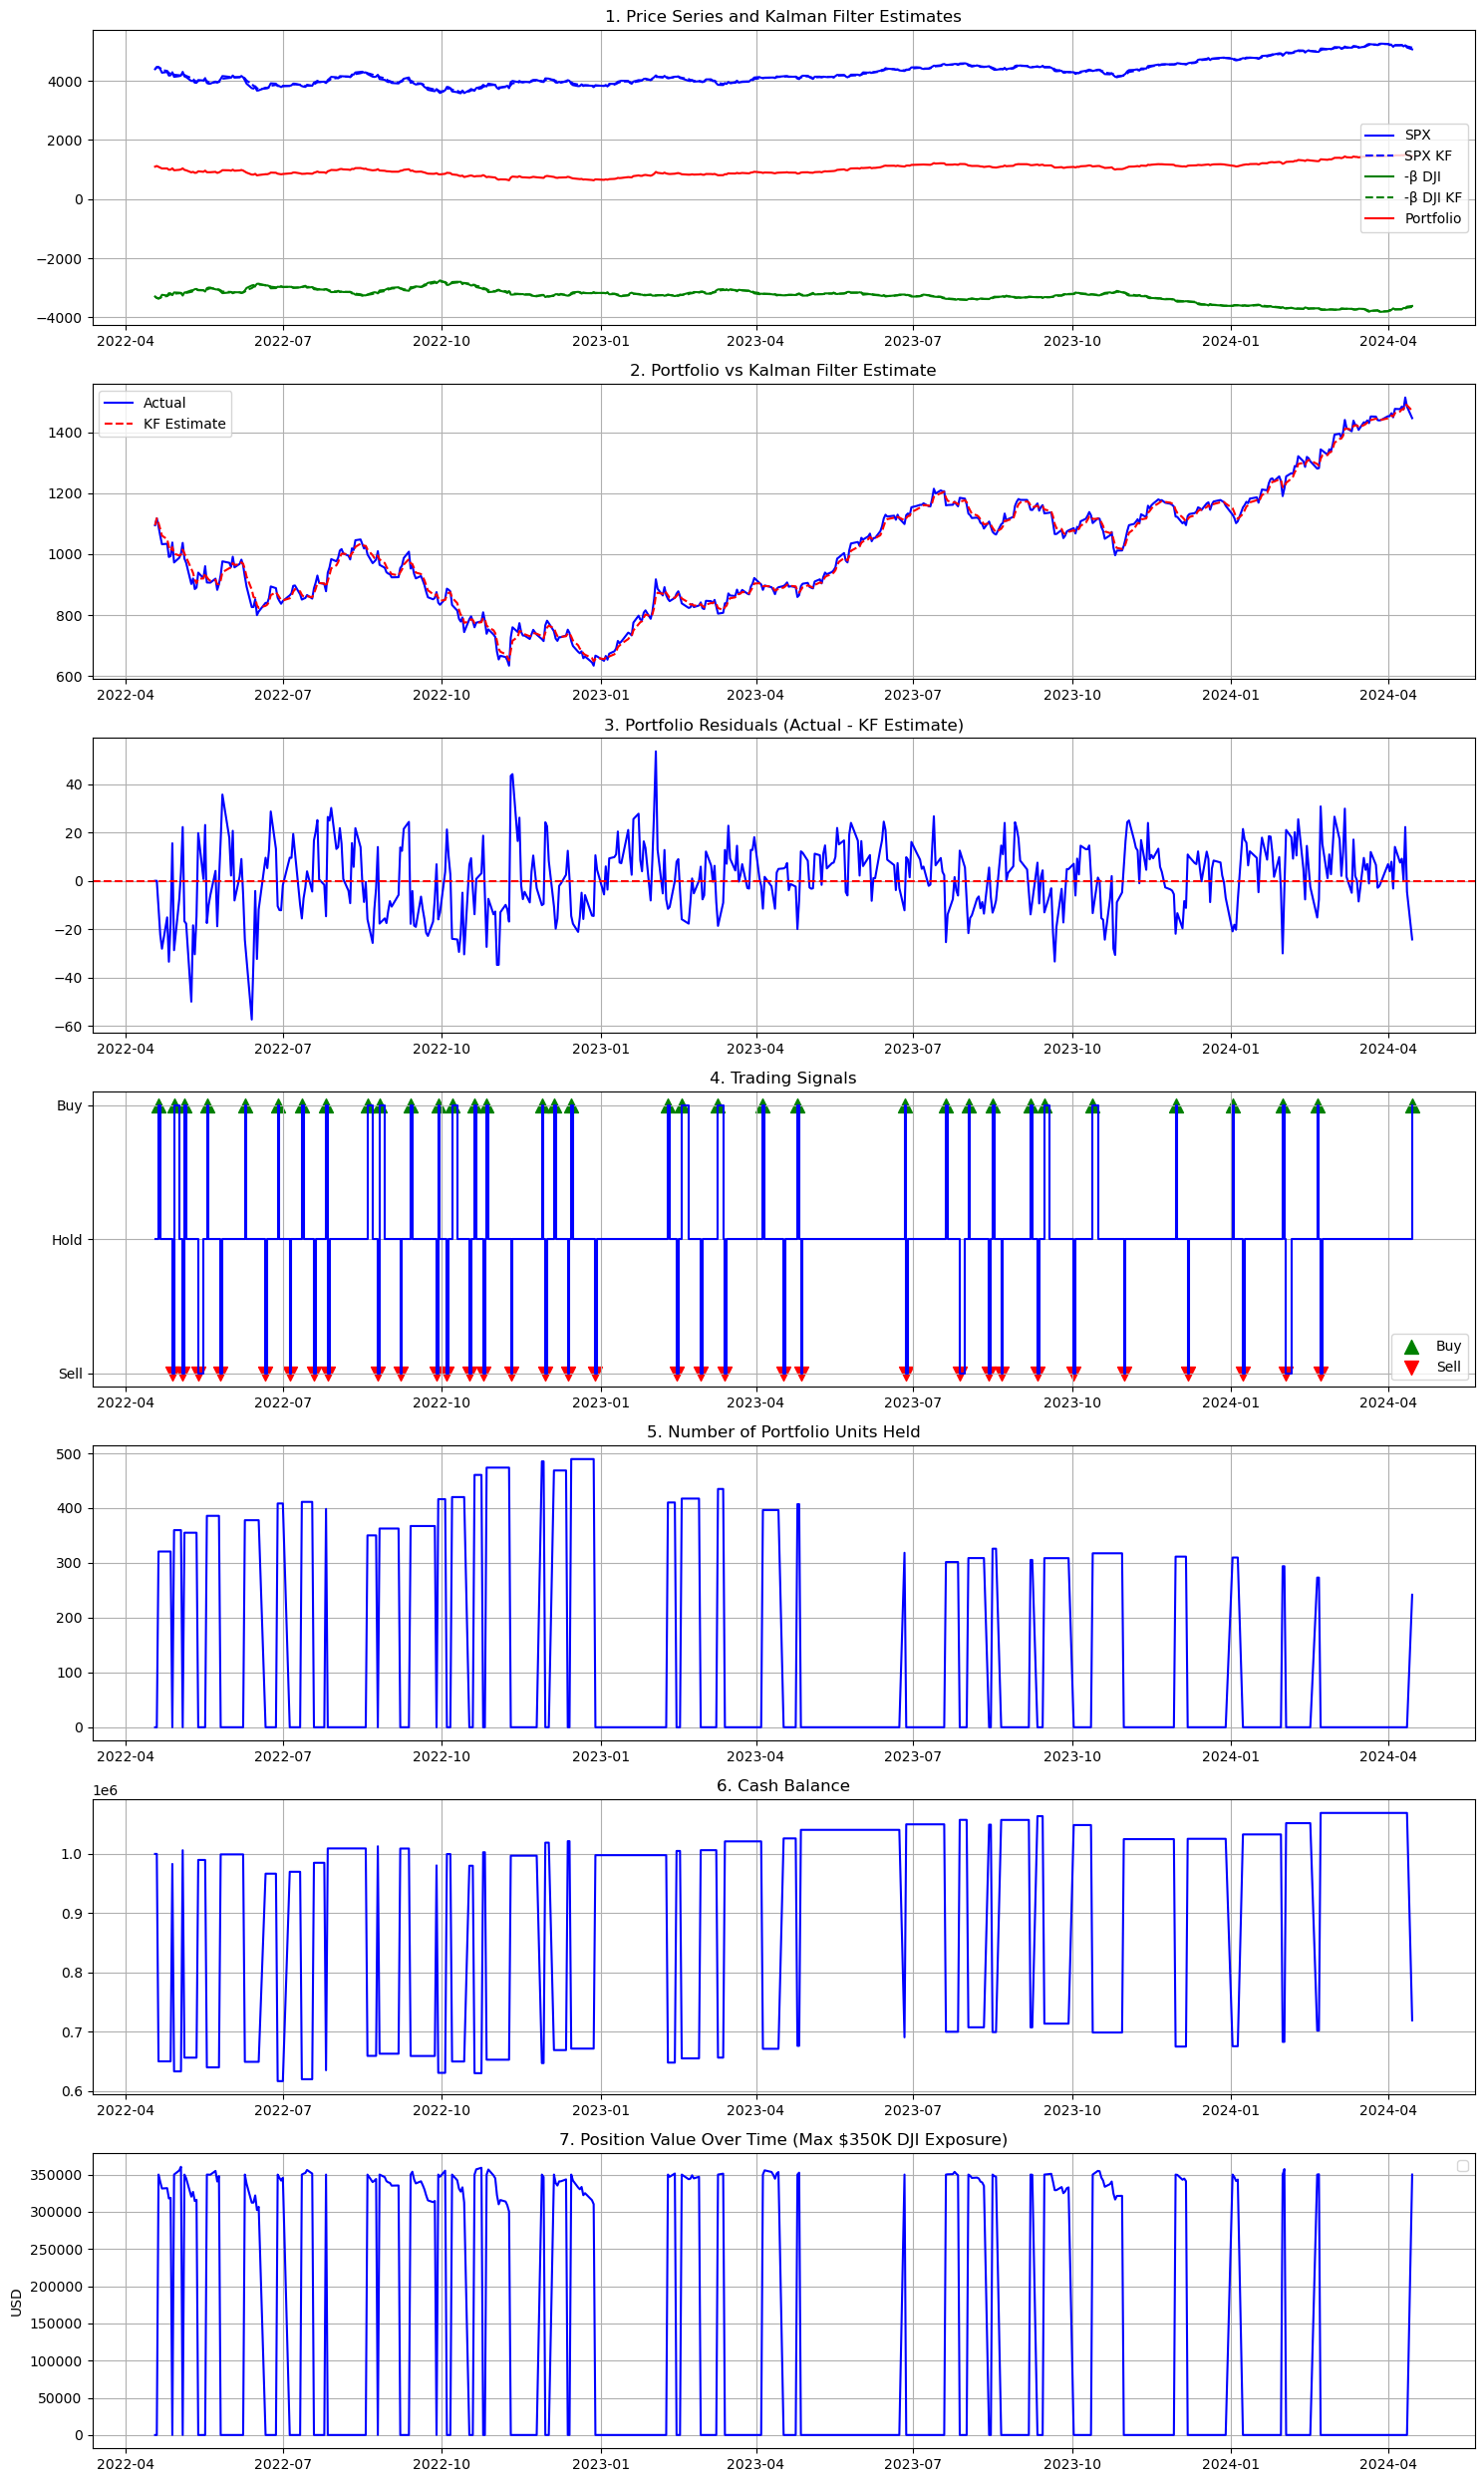


Strategy Performance:
  Initial Capital: $1,000,000
  Final Equity:    $1,069,157.06
  Total Return:    6.92%
  Annualized Vol:  8.53%
  Annualized Sharpe: 0.44
  Max DJI Exposure: $350,000
  Number of Trades: 34

Buy and Hold Benchmarks:
  SPX → Return: 15.26%, Vol: 18.36%, Sharpe: 0.48
  DJI → Return: 9.66%, Vol: 15.39%, Sharpe: 0.38


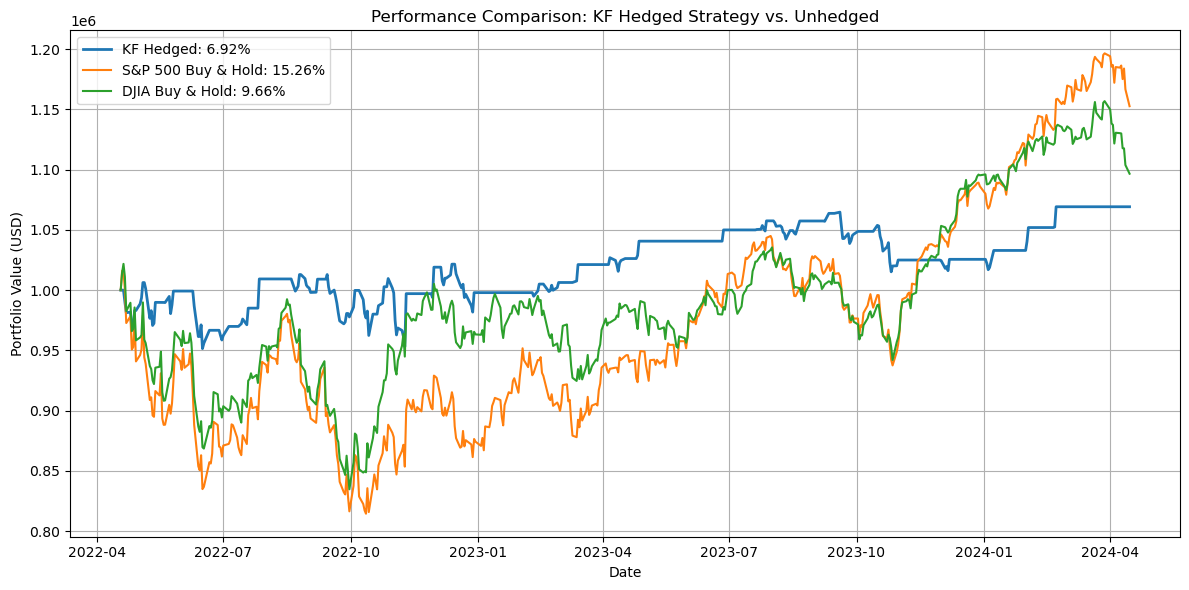

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit

class KalmanPairsTrader:
    def __init__(self, df, primary_col='SPX', hedge_col='DJI'):
        self.df = df.dropna(subset=[primary_col, hedge_col]).copy()
        self.primary_col = primary_col
        self.hedge_col = hedge_col
        self.hedge_ratio = None
        self.kf_params = {'primary': None, 'hedge': None}
        
    def run_kalman_filter(self, y, q_ratio):
        n = len(y)
        x_est = np.zeros(n)
        P = np.zeros(n)
        R = np.var(np.diff(y) / y[:-1])
        Q = q_ratio * R
        F, H  = 1.0, 1.0
        
        x_est[0] = y[0]
        P[0] = 1.0

        for t in range(1, n):
            x_pred = F * x_est[t-1]
            P_pred = F * P[t-1] * F + Q
            K = P_pred * H / (H * P_pred * H + R)
            x_est[t] = x_pred + K * (y[t] - H * x_pred)
            P[t] = (1 - K * H) * P_pred

        return x_est
    
    def optimize_q_ratio(self, y, ratios=np.logspace(-4, -0.5, 10)):
        """Optimize Q/R ratio via time-series cross‐validation"""
        tscv = TimeSeriesSplit(n_splits=3)
        best_mse = float('inf')
        best_r = ratios[0]
        
        for r in ratios:
            mses = []
            for train_idx, val_idx in tscv.split(y):
                train = y[train_idx]
                val = y[val_idx]
                pred = self.run_kalman_filter(val, r)
                mses.append(np.mean((pred - val)**2))
            if np.mean(mses) < best_mse:
                best_mse, best_r = np.mean(mses), r
                
        return best_r
    
    def calculate_hedge_ratio(self, y, x):
        X     = sm.add_constant(x)
        model = sm.OLS(y, X).fit()
        return model.params[1]
    
    def prepare_data(self):
        df = self.df.sort_index()
        df.index = pd.to_datetime(df.index)

        test_df = df.loc['2022-04-17':'2024-04-15']

        pre_test = df.loc[:'2022-04-16']

        n = len(pre_test)
        n_train = int(0.7 * n)

        train_df = pre_test.iloc[:n_train]
        val_df   = pre_test.iloc[n_train:]

        return {
            'train': {'primary': train_df[self.primary_col].values,
                    'hedge':   train_df[self.hedge_col].values,
                    'dates':   train_df.index},
            'val':   {'primary': val_df[self.primary_col].values,
                    'hedge':   val_df[self.hedge_col].values,
                    'dates':   val_df.index},
            'test':  {'primary': test_df[self.primary_col].values,
                    'hedge':   test_df[self.hedge_col].values,
                    'dates':   test_df.index}
        }
    
    def train_model(self):
        """Compute hedge ratio and Kalman Q/R parameters"""
        data = self.prepare_data()
        
        # Hedge ratio on training set
        self.hedge_ratio = self.calculate_hedge_ratio(
            data['train']['primary'],
            data['train']['hedge']
        )
        print(f"Hedge Ratio: {self.hedge_ratio:.4f}")
        
        # Optimize Q/R for primary and hedge (using train+val)
        train_val_p1 = np.concatenate([data['train']['primary'], data['val']['primary']])
        print("\nOptimizing Kalman Filter for primary series")
        self.kf_params['primary'] = self.optimize_q_ratio(train_val_p1)
        print(f"Primary Q/R: {self.kf_params['primary']:.4f}")
        
        train_val_p2 = np.concatenate([data['train']['hedge'], data['val']['hedge']])
        print("Optimizing Kalman Filter for hedge series")
        self.kf_params['hedge'] = self.optimize_q_ratio(train_val_p2)
        print(f"Hedge Q/R: {self.kf_params['hedge']:.4f}")
        
        return data
    
    # def run_strategy(self, entry_thresh=-10, exit_thresh=5):
    #     """Run backtest, plot results, and print performance"""
    #     data = self.train_model()
        
    #     # force true positional indexing on dates
    #     dates_test = np.array(data['test']['dates'])
    #     p1_test = data['test']['primary']
    #     p2_test = data['test']['hedge']
        
    #     # Filtered series
    #     kf_p1 = self.run_kalman_filter(p1_test, self.kf_params['primary'])
    #     kf_p2 = self.run_kalman_filter(p2_test, self.kf_params['hedge'])
        
    #     portfolio = p1_test - self.hedge_ratio * p2_test
    #     kf_portfolio = kf_p1 - self.hedge_ratio * kf_p2
    #     residuals = portfolio - kf_portfolio
        
    #     cash = 1000000
    #     max_dji_expos  = 350000
    #     position = 0
    #     signals = []
    #     pos_vals = []
    #     cash_hist = []
    #     dji_expos_hist = []
    #     trades = []
        
    #     for i in range(len(portfolio)):
    #         date_i = dates_test[i]
    #         port_price = portfolio[i]
    #         dji_price  = p2_test[i]
            
    #         # max units by DJI and cash
    #         max_units = 0
    #         if port_price != 0:
    #             # max_units = min(
    #             #     max_dji_expos / (abs(self.hedge_ratio) * dji_price),
    #             #     cash / abs(port_price)
    #             # )
                
    #             max_units = min(max_dji_expos / abs(port_price), cash / abs(port_price))
            
    #         # entry/exit signals
    #         if residuals[i] <= entry_thresh and position == 0:
    #             sig = 1
    #         elif residuals[i] >= exit_thresh and position > 0:
    #             sig = -1
    #         else:
    #             sig = 0
            
    #         # execute
    #         if sig == 1:
    #             position = max_units
    #             cash -= position * port_price
    #             trades.append(('BUY', date_i, port_price, residuals[i], position))
    #         elif sig == -1:
    #             cash += position * port_price
    #             trades.append(('SELL', date_i, port_price, residuals[i], position))
    #             position = 0
            
    #         signals.append(sig)
    #         pos_vals.append(position * port_price)
    #         cash_hist.append(cash)
    #         dji_expos_hist.append(position * abs(self.hedge_ratio) * dji_price)
        
    #     # Build results DataFrame, including N_Portfolios
    #     results = pd.DataFrame({
    #         'Date':          dates_test,
    #         'Primary':       p1_test,
    #         'Hedge':         p2_test,
    #         'Primary_KF':    kf_p1,
    #         'Hedge_KF':      kf_p2,
    #         'Portfolio':     portfolio,
    #         'Portfolio_KF':  kf_portfolio,
    #         'Residual':      residuals,
    #         'Signal':        signals,
    #         'Position_Value': pos_vals,
    #         'DJI_Value':     dji_expos_hist,
    #         'Cash':          cash_hist,
    #         'Equity':        np.array(cash_hist) + np.array(pos_vals),
    #         'N_Portfolios':  np.array(pos_vals) / np.where(portfolio==0, np.nan, portfolio)
    #     }).set_index('Date')
        
    #     # Plot everything
    #     self._generate_plots(results, trades)
        
    #     # Performance metrics
    #     eq   = results['Equity'].values
    #     rets = np.diff(eq) / eq[:-1]
    #     total_ret = eq[-1] / eq[0] - 1
    #     sharpe    = np.sqrt(252) * np.mean(rets) / np.std(rets)
        
    #     print("\nStrategy Performance:")
    #     print(f"  Initial Capital: ${1_000_000:,}")
    #     print(f"  Final Equity:    ${eq[-1]:,.2f}")
    #     print(f"  Total Return:    {total_ret:.2%}")
    #     print(f"  Annualized Sharpe: {sharpe:.2f}")
    #     print(f"  Max DJI Exposure: ${max_dji_expos:,}")
    #     print(f"  Number of Trades: {len(trades)//2}")
        
        
    #     return results
    def run_strategy(self, entry_thresh=-10, exit_thresh=5):
        """Run backtest, plot results, and print performance"""
        data = self.train_model()
        
        # force true positional indexing on dates
        dates_test = np.array(data['test']['dates'])
        p1_test    = data['test']['primary']
        p2_test    = data['test']['hedge']
        
        # Filtered series
        kf_p1 = self.run_kalman_filter(p1_test, self.kf_params['primary'])
        kf_p2 = self.run_kalman_filter(p2_test, self.kf_params['hedge'])
        
        portfolio     = p1_test - self.hedge_ratio * p2_test
        kf_portfolio  = kf_p1   - self.hedge_ratio * kf_p2
        residuals     = portfolio - kf_portfolio
        
        initial_cash  = 1_000_000
        cash          = initial_cash
        max_dji_expos = 350_000
        position      = 0
        
        signals       = []
        pos_vals      = []
        cash_hist     = []
        dji_expos_hist= []
        trades        = []
        
        for i in range(len(portfolio)):
            date_i     = dates_test[i]
            port_price = portfolio[i]
            dji_price  = p2_test[i]
            
            # size by cash & DJI cap (using spread notional)
            if port_price != 0:
                max_units = min(
                    max_dji_expos / abs(port_price),
                    cash / abs(port_price)
                )
            else:
                max_units = 0
            
            # generate signal
            if residuals[i] <= entry_thresh and position == 0:
                sig = 1
            elif residuals[i] >= exit_thresh and position > 0:
                sig = -1
            else:
                sig = 0
            
            # execute trade
            if sig == 1:
                position = max_units
                cash    -= position * port_price
                trades.append(('BUY', date_i, port_price, residuals[i], position))
            elif sig == -1:
                cash    += position * port_price
                trades.append(('SELL', date_i, port_price, residuals[i], position))
                position = 0
            
            # record histories
            signals.append(sig)
            pos_vals.append(position * port_price)
            cash_hist.append(cash)
            dji_expos_hist.append(position * abs(self.hedge_ratio) * dji_price)
        
        results = pd.DataFrame({
            'Date':           dates_test,
            'Primary':        p1_test,
            'Hedge':          p2_test,
            'Primary_KF':     kf_p1,
            'Hedge_KF':       kf_p2,
            'Portfolio':      portfolio,
            'Portfolio_KF':   kf_portfolio,
            'Residual':       residuals,
            'Signal':         signals,
            'Position_Value': pos_vals,
            'DJI_Value':      dji_expos_hist,
            'Cash':           cash_hist,
            'Equity':         np.array(cash_hist) + np.array(pos_vals),
            'N_Portfolios':   np.array(pos_vals) / np.where(portfolio==0, np.nan, portfolio)
        }).set_index('Date')
        
        self._generate_plots(results, trades)
        
        eq          = results['Equity'].values
        strat_rets  = np.diff(eq) / eq[:-1]
        strat_total = eq[-1] / eq[0] - 1
        strat_sharpe= np.sqrt(252) * np.mean(strat_rets) / np.std(strat_rets)
        strat_vol   = np.std(strat_rets) * np.sqrt(252)
        
        print("\nStrategy Performance:")
        print(f"  Initial Capital: ${initial_cash:,}")
        print(f"  Final Equity:    ${eq[-1]:,.2f}")
        print(f"  Total Return:    {strat_total:.2%}")
        print(f"  Annualized Vol:  {strat_vol:.2%}")
        print(f"  Annualized Sharpe: {strat_sharpe:.2f}")
        print(f"  Max DJI Exposure: ${max_dji_expos:,}")
        print(f"  Number of Trades: {len(trades)//2}")
        
        # Buy & Hold Metrics for benchmarks
        # SPX
        spx_prices = p1_test
        spx_rets   = np.diff(spx_prices) / spx_prices[:-1]
        spx_total  = spx_prices[-1] / spx_prices[0] - 1
        spx_vol    = np.std(spx_rets) * np.sqrt(252)
        spx_sharpe = np.sqrt(252) * np.mean(spx_rets) / np.std(spx_rets)
        
        # DJI
        dji_prices = p2_test
        dji_rets   = np.diff(dji_prices) / dji_prices[:-1]
        dji_total  = dji_prices[-1] / dji_prices[0] - 1
        dji_vol    = np.std(dji_rets) * np.sqrt(252)
        dji_sharpe = np.sqrt(252) * np.mean(dji_rets) / np.std(dji_rets)
        
        print("\nBuy and Hold Benchmarks:")
        print(f"  SPX → Return: {spx_total:.2%}, Vol: {spx_vol:.2%}, Sharpe: {spx_sharpe:.2f}")
        print(f"  DJI → Return: {dji_total:.2%}, Vol: {dji_vol:.2%}, Sharpe: {dji_sharpe:.2f}")
        
        hedged_eq = results['Equity']
        spx_eq    = initial_cash * (spx_prices / spx_prices[0])
        dji_eq    = initial_cash * (dji_prices / dji_prices[0])
        
        plt.figure(figsize=(12, 6))
        plt.plot(results.index, hedged_eq, label=f"KF Hedged: {strat_total:.2%}", linewidth=2)
        plt.plot(results.index, spx_eq,    label=f"S&P 500 Buy & Hold: {spx_total:.2%}")
        plt.plot(results.index, dji_eq,    label=f"DJIA Buy & Hold: {dji_total:.2%}")
        plt.title("Performance Comparison: KF Hedged Strategy vs. Unhedged")
        plt.ylabel("Portfolio Value (USD)")
        plt.xlabel("Date")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()
        
        return results
   
    
    def _generate_plots(self, results, trades):
        """Generate all 7 requested plots with position value in Plot 7"""
        plt.figure(figsize=(15, 25))
        
        # Plot 1: Prices and KF estimates
        plt.subplot(7, 1, 1)
        plt.plot(results.index, results['Primary'], 'b-', label=self.primary_col)
        plt.plot(results.index, results['Primary_KF'], 'b--', label=f'{self.primary_col} KF')
        plt.plot(results.index, -self.hedge_ratio * results['Hedge'],    'g-',  label=f'-β {self.hedge_col}')
        plt.plot(results.index, -self.hedge_ratio * results['Hedge_KF'], 'g--', label=f'-β {self.hedge_col} KF')
        plt.plot(results.index, results['Portfolio'], 'r-', label='Portfolio')
        plt.title('1. Price Series and Kalman Filter Estimates')
        plt.legend()
        plt.grid(True)
        
        # Plot 2: Portfolio vs KF Portfolio
        plt.subplot(7, 1, 2)
        plt.plot(results.index, results['Portfolio'], 'b-', label='Actual')
        plt.plot(results.index, results['Portfolio_KF'], 'r--', label='KF Estimate')
        plt.title('2. Portfolio vs Kalman Filter Estimate')
        plt.legend()
        plt.grid(True)
        
        # Plot 3: Demeaned Portfolio
        plt.subplot(7, 1, 3)
        plt.plot(results.index, results['Residual'], 'b-')
        plt.axhline(0, color='r', linestyle='--')
        plt.title('3. Portfolio Residuals (Actual - KF Estimate)')
        plt.grid(True)
        
        # Plot 4: Signals
        plt.subplot(7, 1, 4)
        plt.step(results.index, results['Signal'], 'b-', where='post')
        buy_dates = [trade[1] for trade in trades if trade[0] == 'BUY']
        sell_dates = [trade[1] for trade in trades if trade[0] == 'SELL']
        plt.scatter(buy_dates, [1]*len(buy_dates), color='g', marker='^', s=100, label='Buy')
        plt.scatter(sell_dates, [-1]*len(sell_dates), color='r', marker='v', s=100, label='Sell')
        plt.yticks([-1, 0, 1], ['Sell', 'Hold', 'Buy'])
        plt.title('4. Trading Signals')
        plt.legend()
        plt.grid(True)
        
        # Plot 5: Number of Portfolio Units
        plt.subplot(7, 1, 5)
        plt.plot(results.index, results['Position_Value']/results['Portfolio'], 'b-')
        plt.title('5. Number of Portfolio Units Held')
        plt.grid(True)
        
        # Plot 6: Cash Balance
        plt.subplot(7, 1, 6)
        plt.plot(results.index, results['Cash'], 'b-')
        plt.title('6. Cash Balance')
        plt.grid(True)
        
        # Plot 7: POSITION VALUE OVER TIME (MODIFIED)
        plt.subplot(7, 1, 7)
        plt.plot(results.index, results['Position_Value'], 'b-')
        plt.title('7. Position Value Over Time (Max $350K DJI Exposure)')
        plt.ylabel('USD')
        plt.legend()
        plt.grid(True)
        
        plt.tight_layout()
        plt.show()

trader = KalmanPairsTrader(df, primary_col='SPX', hedge_col='DJI')
results = trader.run_strategy(entry_thresh=-10, exit_thresh=5)


## Strategy Approach Explanation
- Data Preparation: split into training, validation (I used more time horizon for training and validation sets for better parameters searching), and testing (2022-04-17 to 2024-04-15, I included more data to move the test window into a more mean-reverting regime) periods so that we can do out-of-sample testing of the strategy
    - training set purpose: estimate core parameters like the OLS hedge ratio
    - validation set purpose: Optimize Kalman filter’s process-noise ratio Q/R by minimizing one-step-ahead MSE; choose the ratio that works best on validation so that we wouldn't over-fit the smoothing to the final test
- Training Phase: 
    - calculate the hedge ratio between primary (S&P) and hedge (DJI) assets
    - optimize the Kalman filter parameters using cross-validation; One thing worth mentioned here is that I run two separate 1-D Kalman filters: one on the primary price series (SPX) and one on the hedge series and then form the "filtered spread" by calculating $\
\widehat{\mathrm{Spread}}_{t} \;=\; \widehat{P}_{t}\;-\;\beta\,\widehat{H}_{t}$; By smoothing each price series on its own, we get more accurate, instrument-tailored estimates of fair value, and therefore a much cleaner, mean-reverting residual when we form the hedged spread

- Trading Execution: 
    - Maximum position size is limited by both cash and maximum DJI exposure ($350,000)
    - Positions are taken when residuals (actual portfolio price - kalman fair value) fall below the entry threshold
    - Positions are exited when residuals rise above the exit threshold
- Performance Evaluation

### Key observations from plots
While the hedged strategy underperformed buy-and-hold in our testing period, its superior volatility control and crisis-period resilience make it a valuable diversifier. We can observed that the strategy significantly outperformed during volatile/downward periods (e.g., 2022 bear market), but gave up gains during strong rallies, and this is the characteristic of mean-reversion systems.

FYI: Signal Generation: 

The current signal generation uses fixed thresholds (-10 and 5 in the this example, hard-coded, found through parameter tuning). A more adaptive approach would set thresholds based on the historical distribution of residuals, perhaps using a rolling z-score calculation. This would adapt to changes in the spread's statistical properties over time and likely reduce false signals during volatile periods. I tried this in later pair trading strategies below.

# Q2. Commodity Pair

Review the data provided, and eliminate any unwanted data

In [4]:
file_path = "./NYU_Spr2025_FRE6901_L5-KF_Strategies_v1.xlsx"
df_commodity = pd.read_excel(file_path, skiprows=12)
df_commodity.columns = ['Date', 'HHNGSP', 'WTI']
df_commodity = df_commodity.dropna()
df_commodity['Date'] = pd.to_datetime(df_commodity['Date'])
df_commodity.set_index('Date', inplace=True)
df_commodity.sort_index(inplace=True)
df_commodity

,HHNGSP,WTI
Date,,
1997-01-07,3.82,26.25
1997-01-08,3.80,26.55
1997-01-09,3.61,26.30
1997-01-10,3.92,26.15
1997-01-13,4.00,25.20
...,...,...
2022-04-26,6.89,102.62
2022-04-27,6.91,101.96
2022-04-28,6.97,105.47


/var/folders/cg/xvf2cz356g11zj7b748nl_q00000gn/T/ipykernel_49643/2175340205.py:29: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = sm.OLS(y, X).fit().params[1]


Static hedge ratio β = 0.0428
Optimal Q/R ratio = 1.0000e-01
Using thresholds entry=-0.457, exit=0.200
Strategy Return: 149.51%, Vol: 62.33%, Sharpe: 0.60


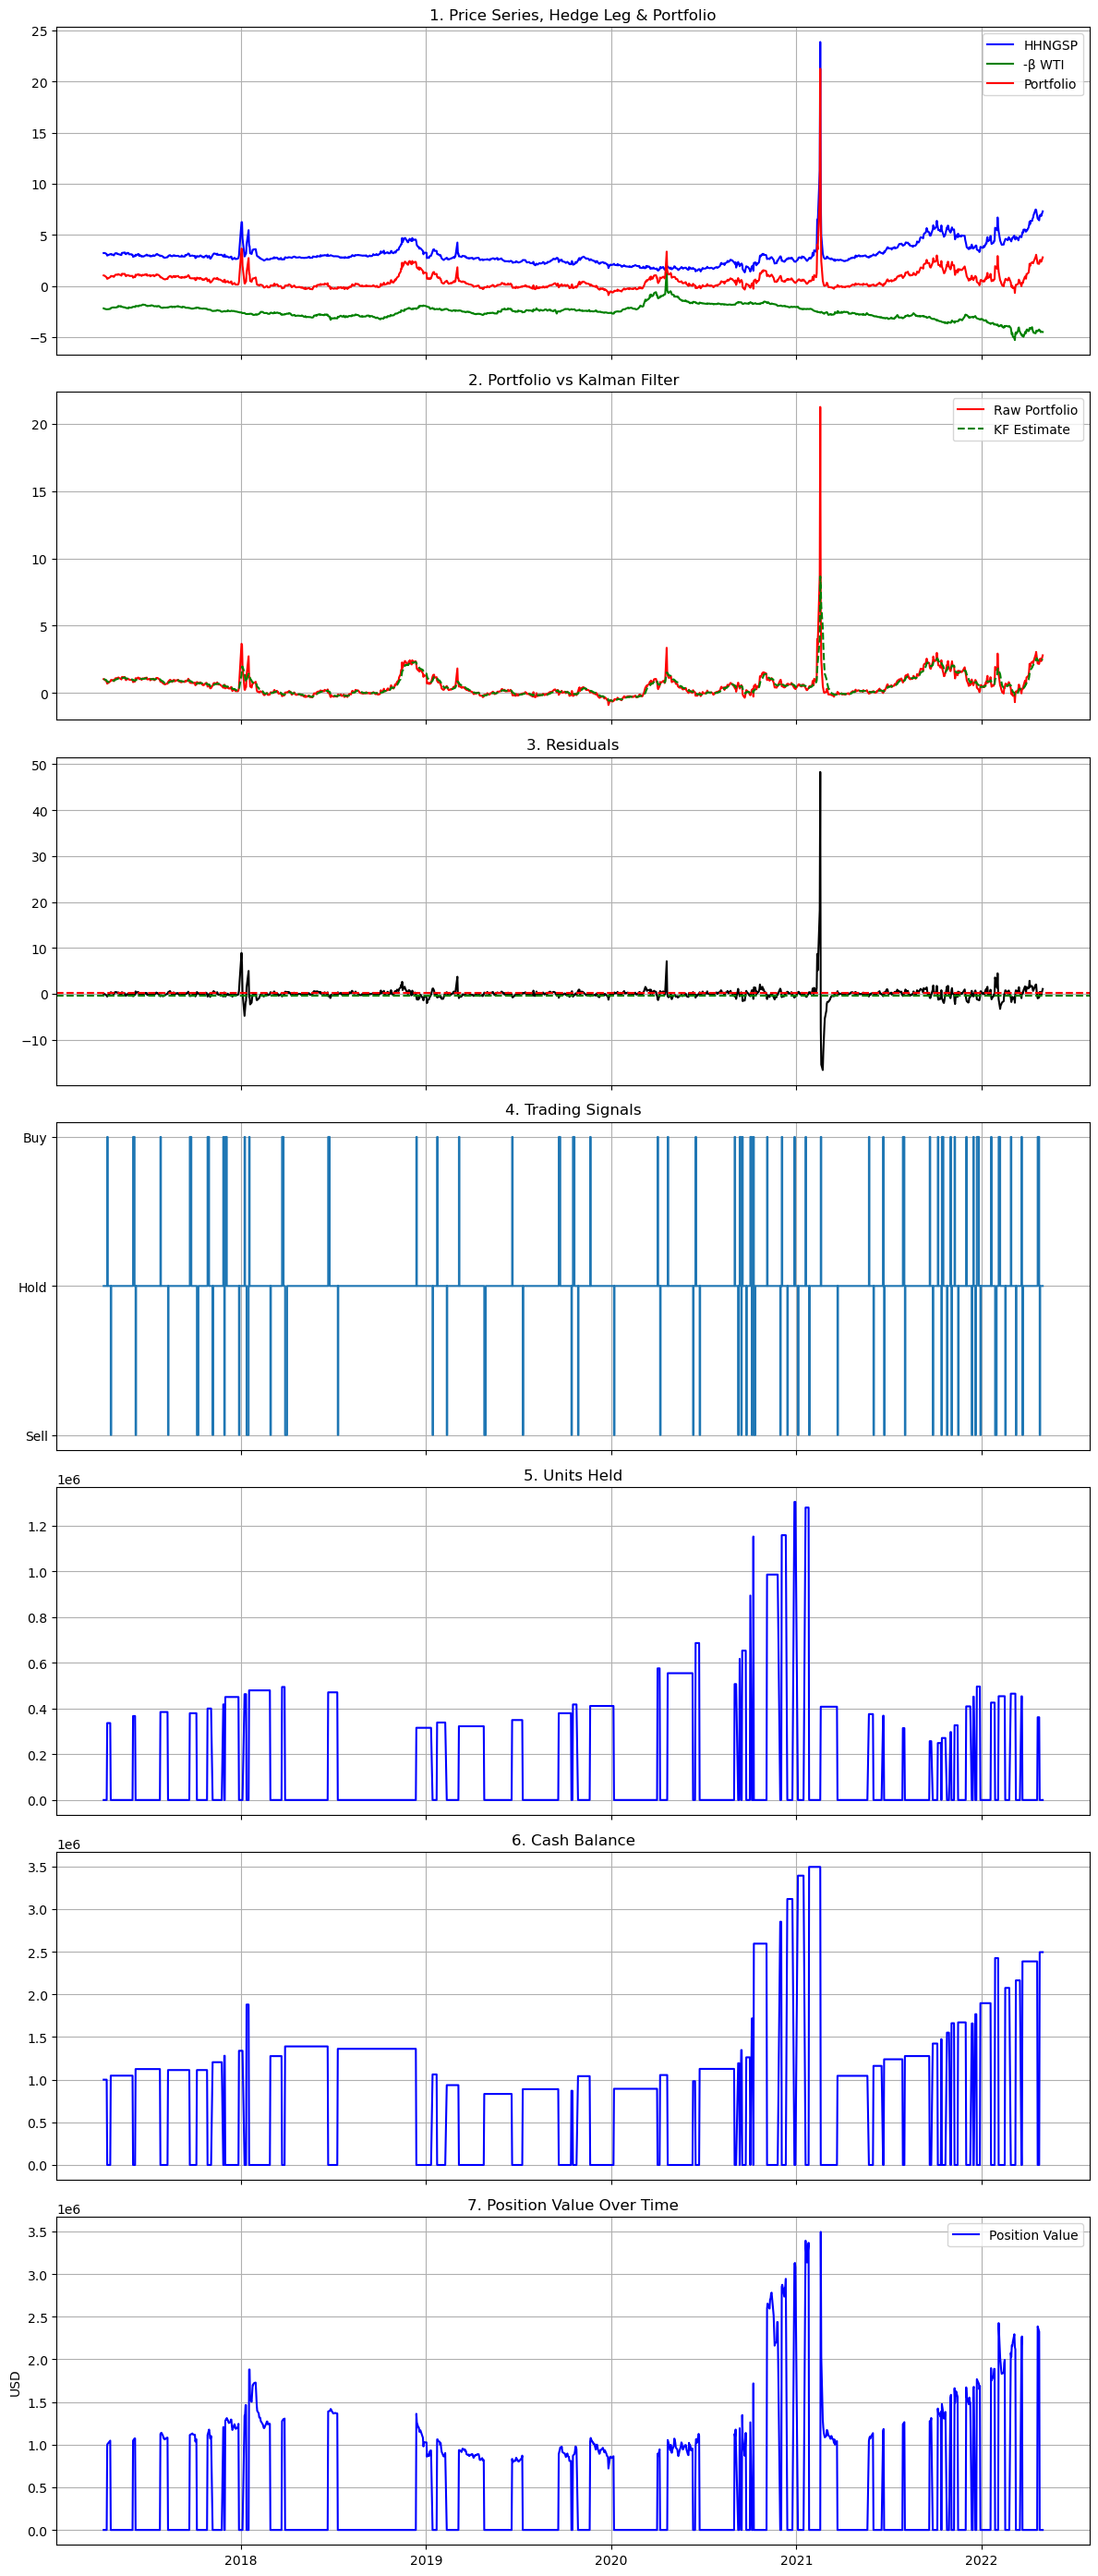

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import TimeSeriesSplit

class CommodityPairStrategy:
    def __init__(self, df, primary_col='GAS', hedge_col='OIL'):
        df = df.copy()
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'])
            df.set_index('Date', inplace=True)
        self.df = df[[primary_col, hedge_col]].dropna().sort_index().astype(float)
        self.primary_col = primary_col
        self.hedge_col   = hedge_col

    def split_data(self):
        n = len(self.df)
        n_train = int(0.6 * n)
        n_val   = int(0.2 * n)
        train = self.df.iloc[:n_train]
        val   = self.df.iloc[n_train:n_train+n_val]
        test  = self.df.iloc[n_train+n_val:]
        return train, val, test

    def static_hedge(self, train):
        X = sm.add_constant(train[self.hedge_col])
        y = train[self.primary_col]
        beta = sm.OLS(y, X).fit().params[1]
        return beta

    def run_kalman_filter(self, y, q_ratio):
        n = len(y)
        x_est = np.zeros(n)
        P     = np.zeros(n)
        R     = np.var(np.diff(y))
        Q     = q_ratio * R
        x_est[0], P[0] = y[0], 1.0
        for t in range(1, n):
            P_pred   = P[t-1] + Q
            K        = P_pred / (P_pred + R)
            x_est[t] = x_est[t-1] + K * (y[t] - x_est[t-1])
            P[t]     = (1 - K) * P_pred
        return x_est

    def optimize_q_ratio(self, series, ratios=None):
        if ratios is None:
            ratios = np.logspace(-4, -1, 20)
        tscv, best_mse = TimeSeriesSplit(n_splits=3), float('inf')
        best_r = ratios[0]
        for r in ratios:
            mses = []
            for tr, vl in tscv.split(series):
                y_val = series[vl]
                pred  = self.run_kalman_filter(y_val, r)
                mses.append(np.mean((pred - y_val)**2))
            m = np.mean(mses)
            if m < best_mse:
                best_mse, best_r = m, r
        return best_r

    def optimize_threshold(self, resid_val, price_val):
        sigma = resid_val.std()
        entry_grid = np.linspace(-2*sigma, -0.2*sigma, 8)
        exit_grid  = np.linspace( 0.2*sigma,  2*sigma, 8)
        best = {'sharpe': -np.inf, 'entry': None, 'exit': None}
        initial = 1e6
        for e in entry_grid:
            for x in exit_grid:
                cash, pos = initial, 0.0
                eq_hist   = []
                for r, p in zip(resid_val, price_val):
                    if r < e and pos == 0:
                        pos  = cash / p
                        cash -= pos * p
                    elif r > x and pos > 0:
                        cash += pos * p
                        pos   = 0.0
                    eq_hist.append(cash + pos * p)
                rets = np.diff(eq_hist)/eq_hist[:-1] if len(eq_hist) > 1 else []
                if len(rets) < 2:
                    continue
                sharpe = np.sqrt(252) * np.mean(rets) / np.std(rets)
                if sharpe > best['sharpe']:
                    best.update({'sharpe': sharpe, 'entry': e, 'exit': x})
        return best.get('entry', -sigma), best.get('exit', sigma)

    def run(self):
        train, val, test = self.split_data()

        beta = self.static_hedge(train)
        print(f"Static hedge ratio β = {beta:.4f}")

        train_pf = train[self.primary_col] - beta * train[self.hedge_col]
        val_pf   = val  [self.primary_col] - beta * val  [self.hedge_col]
        test_pf  = test [self.primary_col] - beta * test [self.hedge_col]

        # Optimize Q/R on train+val
        tv_pf = np.concatenate([train_pf.values, val_pf.values])
        q_ratio = self.optimize_q_ratio(tv_pf)
        print(f"Optimal Q/R ratio = {q_ratio:.4e}")

        # filter train+val for threshold tuning
        kf_tv    = self.run_kalman_filter(tv_pf, q_ratio)
        resid_tv = tv_pf - kf_tv
        n_tr     = len(train_pf)
        resid_val= resid_tv[n_tr:]
        resid_val= (resid_val - resid_val.mean())/resid_val.std()

        # Optimize entry/exit on validation
        entry_z, exit_z = self.optimize_threshold(resid_val, val[self.primary_col].values)
        print(f"Using thresholds entry={entry_z:.3f}, exit={exit_z:.3f}")

        kf_test    = self.run_kalman_filter(test_pf.values, q_ratio)
        resid_test = (test_pf.values - kf_test - resid_tv.mean())/resid_tv.std()

        # backtest on test
        initial = 1e6
        cash, pos = initial, 0.0
        signals, units, cash_hist, strat_eq = [], [], [], []
        for r, p in zip(resid_test, test[self.primary_col].values):
            if r < entry_z and pos == 0:
                pos  = cash / p
                cash -= pos * p
                signals.append(1)
            elif r > exit_z and pos > 0:
                cash += pos * p
                pos   = 0.0
                signals.append(-1)
            else:
                signals.append(0)
            units.append(pos)
            cash_hist.append(cash)
            strat_eq.append(cash + pos * p)
        strat_eq = np.array(strat_eq)

        pos_vals = np.array(units) * test[self.primary_col].values

        rets    = np.diff(strat_eq)/strat_eq[:-1]
        total_r = strat_eq[-1]/initial - 1
        vol     = rets.std()*np.sqrt(252)
        sharpe  = rets.mean()*np.sqrt(252)/rets.std()
        print(f"Strategy Return: {total_r:.2%}, Vol: {vol:.2%}, Sharpe: {sharpe:.2f}")

        # Buy-and-hold benchmarks
        hh_eq  = initial * test[self.primary_col]/test[self.primary_col].iloc[0]
        wti_eq = initial * test[self.hedge_col]/test[self.hedge_col].iloc[0]

        fig, axes = plt.subplots(7,1,figsize=(12,28), sharex=True)

        # 1: Prices, Hedge Leg & Portfolio
        axes[0].plot(test.index, test[self.primary_col], 'b-', label=self.primary_col)
        axes[0].plot(test.index, -beta * test[self.hedge_col], 'g-', label=f'-β {self.hedge_col}')
        axes[0].plot(test.index, test_pf, 'r-', label='Portfolio')
        axes[0].set_title('1. Price Series, Hedge Leg & Portfolio')
        axes[0].legend(); axes[0].grid(True)

        # 2: Portfolio vs Kalman Filter
        axes[1].plot(test.index, test_pf, 'r-', label='Raw Portfolio')
        axes[1].plot(test.index, kf_test, 'g--', label='KF Estimate')
        axes[1].set_title('2. Portfolio vs Kalman Filter')
        axes[1].legend(); axes[1].grid(True)

        # 3: Residuals
        axes[2].plot(test.index, resid_test, 'k-')
        axes[2].axhline(entry_z, color='g', linestyle='--')
        axes[2].axhline(exit_z,  color='r', linestyle='--')
        axes[2].set_title('3. Residuals')
        axes[2].grid(True)

        # 4: Trading Signals
        axes[3].step(test.index, signals, where='post')
        axes[3].set_yticks([-1,0,1]); axes[3].set_yticklabels(['Sell','Hold','Buy'])
        axes[3].set_title('4. Trading Signals')
        axes[3].grid(True)

        # 5: Units Held
        axes[4].plot(test.index, units, 'b-')
        axes[4].set_title('5. Units Held')
        axes[4].grid(True)

        # 6: Cash Balance
        axes[5].plot(test.index, cash_hist, 'b-')
        axes[5].set_title('6. Cash Balance')
        axes[5].grid(True)

        # 7: Position Value Over Time
        axes[6].plot(test.index, pos_vals, 'b-', label='Position Value')
        axes[6].set_title('7. Position Value Over Time')
        axes[6].set_ylabel('USD')
        axes[6].legend(); axes[6].grid(True)

        plt.tight_layout(); plt.show()
        
strat = CommodityPairStrategy(df_commodity, 'HHNGSP', 'WTI')
results = strat.run()


### Comment
62.33% volatility is extremely high. It's typical for commodity markets, which are inherently more volatile than equities.
Also, for this question, we have unconstrained position sizing for commodities (assumption, since the question didn't specify a limit).


While the 149% return is impressive, the 62% volatility reveals dangerous risk-taking. Let's try a dynamic hedging approach, with the hope that it may preserve most returns while cutting volatility.

### Dynamic Hegde Commodity Pair Trading Strategy
How the Kalman Filter works here as a way to find the dynamic hedge ratio: 

The Kalman filter implementation models the hedge ratio as a time-varying state that evolves over time. It works by:
1. Starting with an initial hedge ratio estimate
2. Predicting the next hedge ratio based on the previous one
3. Updating the prediction when new price data arrives
4. continuously adjusting the hedge ratio as market conditions change

Comparsion w/ a static hedge:
- It can adapt to changes in the relationship between commodities
- It can handle regime shifts in the market
- It tends to produce more stable hedged portfolios over time

Train=3804, Val=1268, Test=1268
Optimal q_ratio for spread KF: 1.00e-01
Entry z=-0.000, Exit z=0.000

Strategy Performance
Total Return  : 11.12%
Ann. Return   : 33.78%
Ann. Volatility: 75.92%
Sharpe Ratio  : 0.44


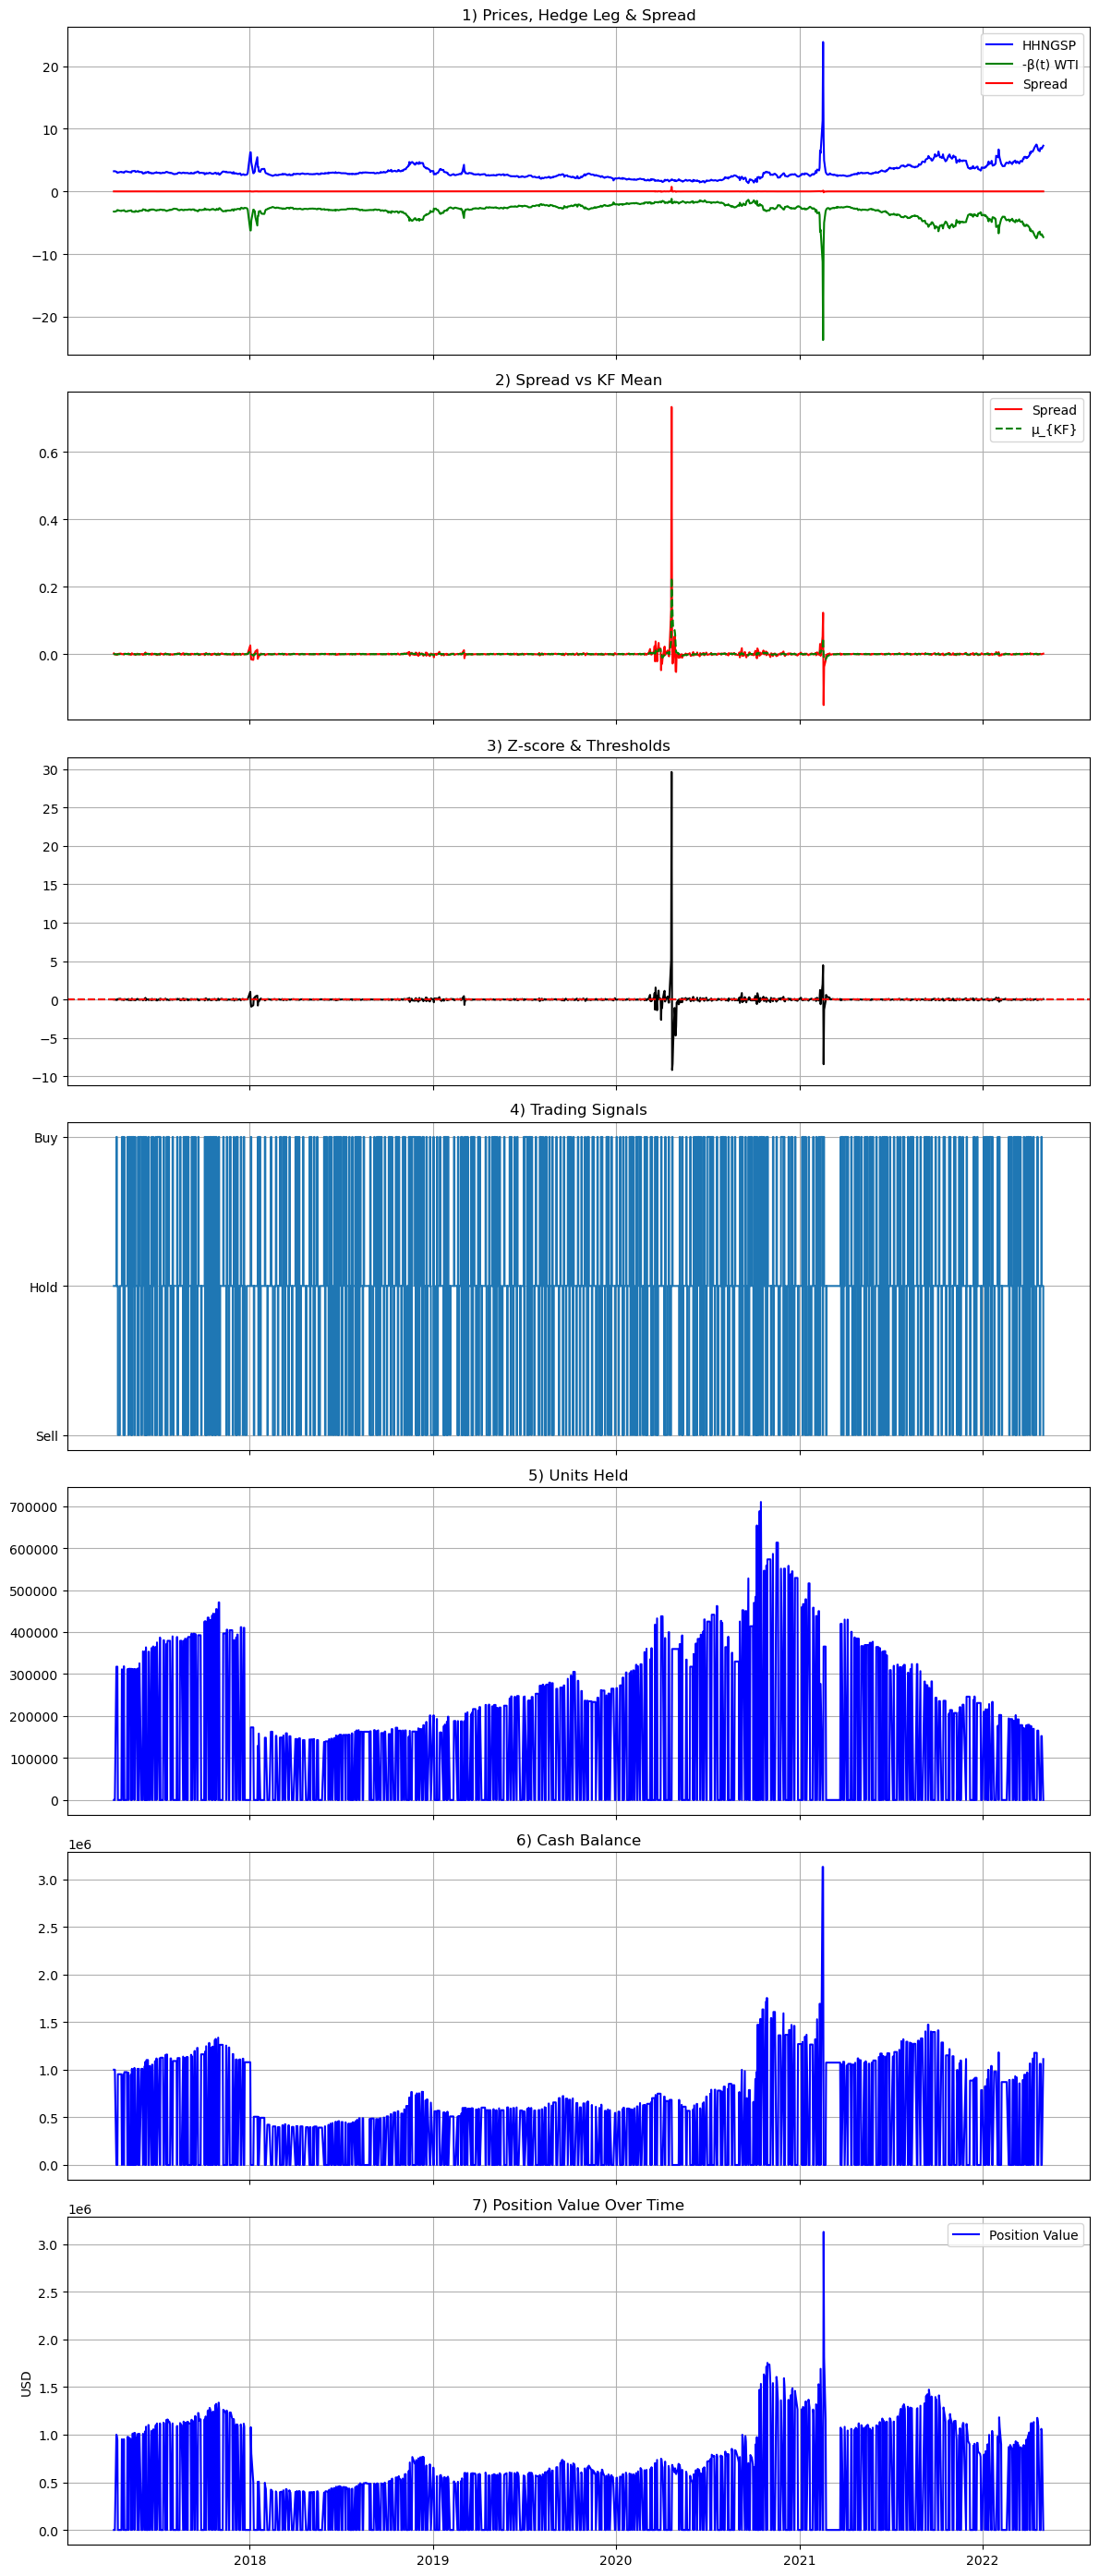

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit

class DualKalmanPairStrategy:
    """
    Dual-Kalman Commodity Pair Trading:
      1) Kalman filter for dynamic hedge ratio β(t)
      2) Kalman filter for spread mean μ(t)
      3) Mean-reversion signals on z = (spread-μ)/σ
    """

    def __init__(self, df, primary_col='HHNGSP', hedge_col='WTI'):
        df = df.copy()
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'])
            df.set_index('Date', inplace=True)

        self.df = df[[primary_col, hedge_col]].dropna().astype(float)
        self.pri = primary_col
        self.hed = hedge_col

    def split_data(self):
        n = len(self.df)
        n1 = int(0.6 * n)
        n2 = int(0.2 * n)
        return (
            self.df.iloc[:n1],
            self.df.iloc[n1:n1+n2],
            self.df.iloc[n1+n2: ],
        )

    def kalman_hedge_ratio(self, data, delta=1e-4, r_var=0.01):
        y = data[self.pri].values
        x = data[self.hed].values
        n = len(y)

        beta = np.zeros(n)
        P    = np.zeros(n)
        beta[0], P[0] = 0.0, 1.0
        R = np.var(np.diff(y)) * r_var

        for t in range(1, n):
            # predict
            b_pred = beta[t-1]
            P_pred = P[t-1] + delta
            # update
            K       = P_pred * x[t] / (P_pred * x[t]**2 + R)
            beta[t] = b_pred + K * (y[t] - b_pred * x[t])
            P[t]    = (1 - K * x[t]) * P_pred

        return pd.Series(beta, index=data.index)

    def kalman_spread_filter(self, spread, q_ratio):
        n = len(spread)
        mu = np.zeros(n)
        P  = np.zeros(n)
        mu[0], P[0] = spread.iloc[0], 1.0
        R = np.nanvar(np.diff(spread)) if n>1 else 1.0
        Q = q_ratio * R

        for t in range(1, n):
            # predict
            mu_pred = mu[t-1]
            P_pred  = P[t-1] + Q
            # update
            K        = P_pred / (P_pred + R)
            mu[t]    = mu_pred + K * (spread.iloc[t] - mu_pred)
            P[t]     = (1 - K) * P_pred

        return pd.Series(mu, index=spread.index)

    def optimize_q_ratio(self, spread, ratios=None):
        if ratios is None:
            ratios = np.logspace(-4, -1, 20)
        tscv, best, best_r = TimeSeriesSplit(3), np.inf, ratios[0]
        for r in ratios:
            mses = []
            for tr, vl in tscv.split(spread):
                yv = spread.iloc[vl]
                mu = self.kalman_spread_filter(yv, r)
                mses.append(((yv - mu)**2).mean())
            m = np.mean(mses)
            if m < best:
                best, best_r = m, r
        return best_r

    def optimize_thresholds(self, resid, prices):
        σ = resid.std()
        entries = np.linspace(-2*σ, -0.5*σ, 8)
        exits   = np.linspace( 0.5*σ,  2*σ, 8)
        best = {'sh': -np.inf, 'e': -1.5*σ, 'x': 1.5*σ}
        init = 1e6

        for e in entries:
            for x in exits:
                c, pos, eq = init, 0.0, []
                for r,p in zip(resid, prices):
                    if r < e and pos==0:
                        pos = c/p; c = 0.0
                    elif r > x and pos>0:
                        c = pos*p; pos = 0.0
                    eq.append(c + pos*p)
                rets = np.diff(eq)/eq[:-1] if len(eq)>1 else []
                if len(rets)>2:
                    sh = np.sqrt(252)*rets.mean()/rets.std()
                    if sh > best['sh']:
                        best.update({'sh':sh, 'e':e, 'x':x})

        return best['e'], best['x']

    def run(self):
        train, val, test = self.split_data()
        print(f"Train={len(train)}, Val={len(val)}, Test={len(test)}")

        # estimate dynamic β(t)
        betas_train = self.kalman_hedge_ratio(train)
        betas_val   = self.kalman_hedge_ratio(pd.concat([train.iloc[-30:], val]))
        betas_val   = betas_val.iloc[30:]
        betas_test  = self.kalman_hedge_ratio(pd.concat([val.iloc[-30:], test]))
        betas_test  = betas_test.iloc[30:]

        # 2) compute spread on each set
        spread_train = train[self.pri] - betas_train * train[self.hed]
        spread_val   = val[self.pri]   - betas_val   * val[self.hed]
        spread_test  = test[self.pri]  - betas_test  * test[self.hed]

        # fit second KF on train+val to pick q
        all_spread    = pd.concat([spread_train, spread_val])
        q_opt         = self.optimize_q_ratio(all_spread)
        print(f"Optimal q_ratio for spread KF: {q_opt:.2e}")

        mu_test       = self.kalman_spread_filter(spread_test, q_opt)
        resid_test    = spread_test - mu_test

        # find best entry/exit on validation
        mu_val        = self.kalman_spread_filter(spread_val, q_opt)
        e_z, x_z      = self.optimize_thresholds(spread_val - mu_val,
                                                 val[self.pri].values)
        print(f"Entry z={e_z:.3f}, Exit z={x_z:.3f}")

        # backtest on test
        cash, pos, eq = 1e6, 0.0, []
        signals, units, cash_hist, pos_val = [],[],[],[]
        for r, p in zip(resid_test, test[self.pri].values):
            if r < e_z and pos==0:
                pos = cash/p; cash=0.0; signals.append(1)
            elif r > x_z and pos>0:
                cash = pos*p; pos=0.0; signals.append(-1)
            else:
                signals.append(0)
            units.append(pos)
            cash_hist.append(cash)
            pos_val.append(pos*p)
            eq.append(cash + pos*p)

        eq = np.array(eq)
        rets = np.diff(eq)/eq[:-1] if len(eq)>1 else []

        # performance
        total_ret = eq[-1]/1e6 - 1
        ann_ret   = (1 + rets.mean())**252 - 1 if len(rets)>1 else 0
        ann_vol   = rets.std()*np.sqrt(252) if len(rets)>1 else 0
        sharpe    = ann_ret/ann_vol if ann_vol>0 else 0

        print(f"\nStrategy Performance")
        print(f"Total Return  : {total_ret:.2%}")
        print(f"Ann. Return   : {ann_ret:.2%}")
        print(f"Ann. Volatility: {ann_vol:.2%}")
        print(f"Sharpe Ratio  : {sharpe:.2f}")
        
        idx = test.index
        fig, ax = plt.subplots(7,1,figsize=(12,28), sharex=True)
        # 1) Prices & dynamic hedge leg & spread
        ax[0].plot(idx, test[self.pri],'b', label=self.pri)
        ax[0].plot(idx, -betas_test*test[self.hed],'g', label='-β(t) '+self.hed)
        ax[0].plot(idx, spread_test,'r', label='Spread')
        ax[0].set_title("1) Prices, Hedge Leg & Spread"); ax[0].legend(); ax[0].grid()
        # 2) Spread vs mu
        ax[1].plot(idx, spread_test,'r', label='Spread')
        ax[1].plot(idx, mu_test,'g--',label='μ_{KF}')
        ax[1].set_title("2) Spread vs KF Mean"); ax[1].legend(); ax[1].grid()
        # 3) Residual z
        z_test = resid_test/ resid_test.std()
        ax[2].plot(idx, z_test,'k')
        ax[2].axhline(e_z, color='g',ls='--')
        ax[2].axhline(x_z, color='r',ls='--')
        ax[2].set_title("3) Z‐score & Thresholds"); ax[2].grid()
        # 4) signals
        ax[3].step(idx, signals, where='post')
        ax[3].set_yticks([-1,0,1]); ax[3].set_yticklabels(['Sell','Hold','Buy'])
        ax[3].set_title("4) Trading Signals"); ax[3].grid()
        # 5) units
        ax[4].plot(idx, units,'b'); ax[4].set_title("5) Units Held"); ax[4].grid()
        # 6) cash
        ax[5].plot(idx, cash_hist,'b'); ax[5].set_title("6) Cash Balance"); ax[5].grid()
        # 7) position value
        ax[6].plot(idx, pos_val,'b', label='Position Value')
        ax[6].set_title("7) Position Value Over Time"); ax[6].set_ylabel("USD")
        ax[6].legend(); ax[6].grid()
        plt.tight_layout(); plt.show()

        return {
            'betas'      : betas_test,
            'spread'     : spread_test,
            'mu'         : mu_test,
            'zscore'     : z_test,
            'signals'    : signals,
            'positions'  : units,
            'cash_hist'  : cash_hist,
            'position_values': pos_val,
            'equity'     : eq,
            'metrics'    : {
                'total_return': total_ret,
                'annual_return': ann_ret,
                'annual_vol': ann_vol,
                'sharpe': sharpe
            }
        }

strat = DualKalmanPairStrategy(df_commodity, 'HHNGSP', 'WTI')
results = strat.run()


### Comment
When we pit our dual‐Kalman “dynamic” strategy (11.1 % total return, 75.9 % p.a. vol, Sharpe 0.44) against a simple static‐-OLS hedge (149.5 % total return, 62.3 % p.a. vol, Sharpe 0.60), the static hedge handily outperforms. dk why...


Few ways can be explored in future to improve on this baseline:
- Regime‐aware dynamic hedging: rather than re‐estimating β every day, first use a simple regime filter (e.g. 30-day GAS/OIL momentum or volatility) to decide if we’re in a stable cointegrated regime or a trending regime. Only apply the dynamic β(t) in the former, and revert to a static β in the latter to avoid whipsaws.
- Robust noise assumptions: the standard Kalman assumes Gaussian noise, but commodity prices often have spikes and heavy tails. Try using a Student-t Kalman filter or an adaptive noise estimator that down‐weights outliers when computing R and Q
- Rolling re-estimation of Q/R and thresholds

# Q3. 3 FX Pairs

Review the data provided, and use ONLY the market-close data for the 3 currency pairs

In [17]:
file_path = "./NYU_Spr2025_FRE6901_L5-KF_Strategies_v1-2.xlsx"
df_FX = pd.read_excel(file_path, skiprows=7)
df_FX = df_FX.dropna()
df_FX['Date'] = pd.to_datetime(df_FX['Date'])
df_FX.set_index('Date', inplace=True)
df_FX.sort_index(inplace=True)
df_FX

,EUR/USD Close,EUR/USD High,EUR/USD Low,GBP/USD Close,GBP/USD High,GBP/USD Low,EUR/GBP Close,EUR/GBP High,EUR/GBP Low
Date,,,,,,,,,
2020-04-06,1.0800,1.0836,1.0772,1.2307,1.2327,1.2211,0.8773,0.8856,0.8766
2020-04-07,1.0904,1.0926,1.0784,1.2338,1.2385,1.2170,0.8836,0.8862,0.8801
2020-04-08,1.0866,1.0903,1.0830,1.2395,1.2420,1.2288,0.8764,0.8839,0.8746
2020-04-09,1.0929,1.0952,1.0841,1.2453,1.2483,1.2362,0.8773,0.8788,0.8726
2020-04-10,1.0943,1.0952,1.0919,1.2471,1.2487,1.2446,0.8773,0.8787,0.8760
...,...,...,...,...,...,...,...,...,...
2020-11-27,1.1953,1.1962,1.1907,1.3298,1.3382,1.3294,0.8988,0.8993,0.8915
2020-11-30,1.1954,1.2005,1.1942,1.3354,1.3385,1.3306,0.8951,0.9001,0.8946
2020-12-01,1.2046,1.2054,1.1925,1.3423,1.3440,1.3317,0.8971,0.9009,0.8930


In [32]:
close_col = ['EUR/USD Close', 'GBP/USD Close', 'EUR/GBP Close']
df_FX = df_FX[close_col]
df_FX.columns = ['EUR/USD', 'GBP/USD', 'EUR/GBP']
df_FX

,EUR/USD,GBP/USD,EUR/GBP
Date,,,
2020-04-06,1.0800,1.2307,0.8773
2020-04-07,1.0904,1.2338,0.8836
2020-04-08,1.0866,1.2395,0.8764
2020-04-09,1.0929,1.2453,0.8773
2020-04-10,1.0943,1.2471,0.8773
...,...,...,...
2020-11-27,1.1953,1.3298,0.8988
2020-11-30,1.1954,1.3354,0.8951
2020-12-01,1.2046,1.3423,0.8971


### Core Concept: Triangular Arbitrage
The strategy is based on the no-arbitrage condition in FX markets, where the exchange rate between two currencies (e.g., EUR/USD) should theoretically equal the product of exchange rates through a third currency (EUR/GBP × GBP/USD). The strategy constructs a mean-reverting spread

### Logic
Hedge Ratio Calculation Methods
1. Triangular Method (`hedge_method='triangular'`)
- Uses fixed ratios: β₁ = 1, β₂ = 1
- Based on pure arbitrage condition:  
  `EUR/USD = EUR/GBP × GBP/USD`
- Pros: Simple, theoretically sound  
- Cons: Doesn't account for market frictions

2. OLS Regression (`hedge_method='ols'`)
- Estimates β₁ and β₂ via Ordinary Least Squares
- Pros: Adapts to empirical market behavior  
- Cons: May overfit historical data

Kalman Filter Implementation
- Dynamically estimates fair value of spread
- Features:
  - Predict-update cycle for real-time adaptation
  - Optimized process noise (Q) via time-series CV
  - Balances responsiveness and stability

Signal Generation
1. Calculates residuals (spread - Kalman estimate)
2. Optimizes thresholds to maximize Sharpe ratio:
   - Entry when residuals < lower threshold (oversold)
   - Exit when residuals > upper threshold (reversion)


Using triangular hedge ratios β_ab=1, β_bc=1.
Optimal Q/R = 1.0e-01
Entry z=-0.000, Exit z=0.000
Return: 0.28%, Sharpe: 3.57


/var/folders/cg/xvf2cz356g11zj7b748nl_q00000gn/T/ipykernel_49643/3122673450.py:108: RuntimeWarning: invalid value encountered in scalar divide
  sh = np.sqrt(252)*np.mean(rets)/np.std(rets)


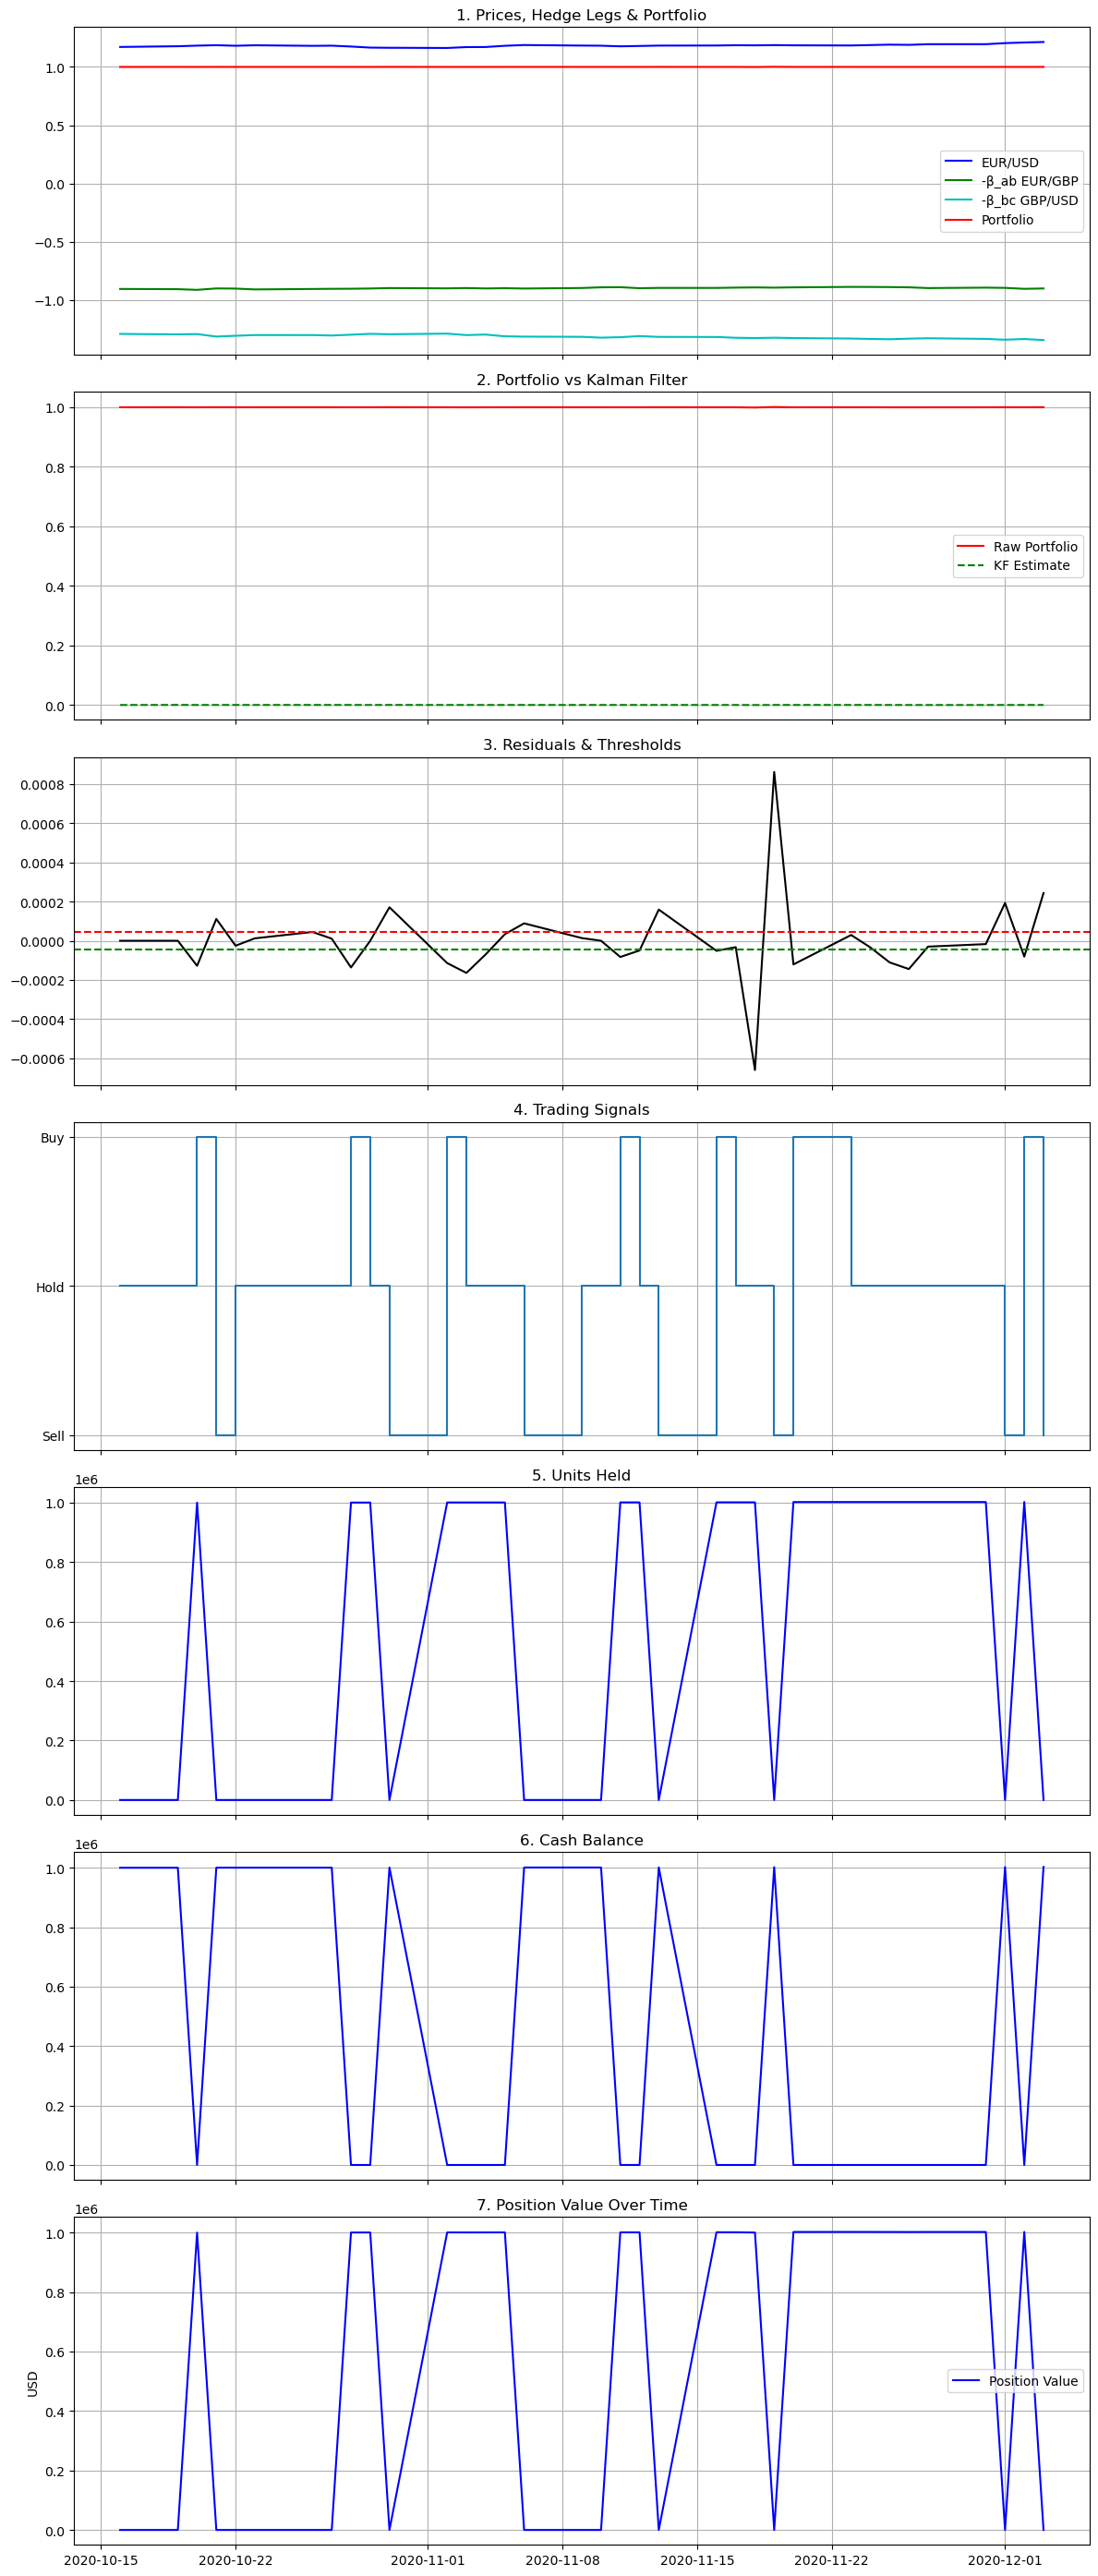

In [ ]:
class FXTriangularStrategy:
    """
    Mean reversion on triangular FX:
      spread_t = log(EUR/USD) - β1·log(EUR/GBP) - β2·log(GBP/USD)

    Hedge methods:
      - 'triangular': use β1=1, β2=1 
      - 'ols':        estimate β1, β2 via OLS on training set
    """
    def __init__(self,
                 df,
                 ab='EUR/GBP',
                 bc='GBP/USD',
                 ac='EUR/USD',
                 hedge_method='triangular',
                 hedge_window=60):
        df = df.copy()
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'])
            df.set_index('Date', inplace=True)

        self.ab = df[ab].astype(float)
        self.bc = df[bc].astype(float)
        self.ac = df[ac].astype(float)

        self.hedge_method = hedge_method.lower()
        self.hedge_window  = hedge_window
        self.beta_ab = None
        self.beta_bc = None

    def split(self):
        n = len(self.ac)
        n_train = int(0.6 * n)
        n_val   = int(0.2 * n)
        idx = self.ac.index
        return idx[:n_train], idx[n_train:n_train+n_val], idx[n_train+n_val:]

    def compute_hedge_ratios(self, train_idx):
        if self.hedge_method == 'triangular':
            self.beta_ab = 1.0
            self.beta_bc = 1.0
            print("Using triangular hedge ratios β_ab=1, β_bc=1.")
        else:
            log_ac = np.log(self.ac.loc[train_idx])
            dfX = pd.DataFrame({
                'log_ab': np.log(self.ab.loc[train_idx]),
                'log_bc': np.log(self.bc.loc[train_idx])
            })
            X = sm.add_constant(dfX)
            model = sm.OLS(log_ac, X).fit()
            self.beta_ab = model.params['log_ab']
            self.beta_bc = model.params['log_bc']
            print(f"OLS hedge ratios: β_ab={self.beta_ab:.4f}, β_bc={self.beta_bc:.4f}")

    def kalman_filter(self, y, q):
        n = len(y)
        x = np.zeros(n)
        P = np.zeros(n)
        R = np.var(np.diff(y))
        Q = q * R
        x[0], P[0] = y[0], 1.0
        for t in range(1, n):
            Pp = P[t-1] + Q
            K  = Pp / (Pp + R)
            x[t] = x[t-1] + K * (y[t] - x[t-1])
            P[t] = (1 - K) * Pp
        return x

    def optimize_q(self, series):
        ratios = np.logspace(-4, -1, 20)
        cv = TimeSeriesSplit(3)
        best_mse, best_q = np.inf, ratios[0]
        for q in ratios:
            errs = []
            for tr, vl in cv.split(series):
                y_val = series[vl]
                pred  = self.kalman_filter(y_val, q)
                errs.append(np.mean((pred - y_val)**2))
            m = np.mean(errs)
            if m < best_mse:
                best_mse, best_q = m, q
        return best_q

    def optimize_thresh(self, resid, price):
        sigma = resid.std()
        entries = np.linspace(-2*sigma, -0.2*sigma, 5)
        exits   = np.linspace( 0.2*sigma,  2*sigma, 5)
        best = {'sh': -np.inf, 'e': -sigma, 'x': sigma}
        init = 1e6
        for e in entries:
            for x in exits:
                c, h, eqh = init, 0.0, []
                for r, p in zip(resid, price):
                    if r < e and h == 0:
                        h = c / p; c -= h * p
                    elif r > x and h > 0:
                        c += h * p; h = 0.0
                    eqh.append(c + h * p)
                rets = np.diff(eqh) / eqh[:-1] if len(eqh)>1 else np.array([])
                if len(rets)>2:
                    sh = np.sqrt(252)*np.mean(rets)/np.std(rets)
                    if sh > best['sh']:
                        best.update({'sh': sh, 'e': e, 'x': x})
        return best['e'], best['x']

    def run(self):
        train_i, val_i, test_i = self.split()

        self.compute_hedge_ratios(train_i)

        log_sp   = ( np.log(self.ac)
                   - self.beta_ab * np.log(self.ab)
                   - self.beta_bc * np.log(self.bc) )
        pf_price = np.exp(log_sp)

        train_sp = log_sp.loc[train_i].values
        val_sp   = log_sp.loc[val_i].values
        test_sp  = log_sp.loc[test_i].values
        train_pf = pf_price.loc[train_i].values
        val_pf   = pf_price.loc[val_i].values
        test_pf  = pf_price.loc[test_i].values

        # optimize Q on train+val
        q_opt = self.optimize_q(np.concatenate([train_sp, val_sp]))
        print(f"Optimal Q/R = {q_opt:.1e}")

        # tune thresholds on val
        kf_tv     = self.kalman_filter(np.concatenate([train_sp, val_sp]), q_opt)
        resid_tv  = np.concatenate([train_sp, val_sp]) - kf_tv
        resid_val = resid_tv[len(train_sp):]
        entry_z, exit_z = self.optimize_thresh(resid_val, val_pf)
        print(f"Entry z={entry_z:.3f}, Exit z={exit_z:.3f}")

        # filter test
        kf_test    = self.kalman_filter(test_sp, q_opt)
        resid_test = test_sp - kf_test

        # backtest
        init, cash, pos = 1e6, 1e6, 0.0
        sigs, units, c_hist, pos_val = [], [], [], []
        for r, p in zip(resid_test, test_pf):
            if r < entry_z and pos==0:
                pos = cash/p; cash -= pos*p; sigs.append(1)
            elif r > exit_z and pos>0:
                cash += pos*p; pos=0.0; sigs.append(-1)
            else:
                sigs.append(0)
            units.append(pos); c_hist.append(cash); pos_val.append(pos*p)

        # metrics
        eq   = np.array(c_hist) + np.array(pos_val)
        rets = np.diff(eq)/eq[:-1] if len(eq)>1 else np.array([])
        print(f"Return: {eq[-1]/init-1:.2%}, Sharpe: {np.sqrt(252)*rets.mean()/rets.std():.2f}")

        fig, axes = plt.subplots(7,1,figsize=(12,28),sharex=True)

        # 1: FX prices, hedge legs & portfolio
        axes[0].plot(test_i, self.ac.loc[test_i],     'b-', label='EUR/USD')
        axes[0].plot(test_i, -self.beta_ab*self.ab.loc[test_i], 'g-', label=f'-β_ab EUR/GBP')
        axes[0].plot(test_i, -self.beta_bc*self.bc.loc[test_i], 'c-', label=f'-β_bc GBP/USD')
        axes[0].plot(test_i, test_pf,                 'r-', label='Portfolio')
        axes[0].set_title('1. Prices, Hedge Legs & Portfolio'); axes[0].legend(); axes[0].grid(True)

        # 2: Portfolio vs KF
        axes[1].plot(test_i, test_pf, 'r-', label='Raw Portfolio')
        axes[1].plot(test_i, kf_test, 'g--',label='KF Estimate')
        axes[1].set_title('2. Portfolio vs Kalman Filter'); axes[1].legend(); axes[1].grid(True)

        # 3: Residuals & thresh
        axes[2].plot(test_i, resid_test, 'k-')
        axes[2].axhline(entry_z, color='g', ls='--')
        axes[2].axhline(exit_z,  color='r', ls='--')
        axes[2].set_title('3. Residuals & Thresholds'); axes[2].grid(True)

        # 4: Signals
        axes[3].step(test_i, sigs, where='post')
        axes[3].set_yticks([-1,0,1]); axes[3].set_yticklabels(['Sell','Hold','Buy'])
        axes[3].set_title('4. Trading Signals'); axes[3].grid(True)

        # 5: Units held
        axes[4].plot(test_i, units, 'b-'); axes[4].set_title('5. Units Held'); axes[4].grid(True)

        # 6: Cash balance
        axes[5].plot(test_i, c_hist, 'b-'); axes[5].set_title('6. Cash Balance'); axes[5].grid(True)

        # 7: Position value
        axes[6].plot(test_i, pos_val, 'b-', label='Position Value')
        axes[6].set_title('7. Position Value Over Time'); axes[6].set_ylabel('USD')
        axes[6].legend(); axes[6].grid(True)

        plt.tight_layout()
        plt.show()

        # 11) return a DataFrame
        return pd.DataFrame({
            'Resid':    resid_test,
            'Signal':   sigs,
            'Units':    units,
            'Position': pos_val,
            'Cash':     c_hist,
            'Equity':   eq
        }, index=test_i)

strat = FXTriangularStrategy(df_FX, hedge_method='triangular')
results = strat.run()


## Future Recommendations for Improving Kalman-Based Pairs Trading
1. Model Enhancements:

The Kalman filter approach could be improved by implementing a more comprehensive state-space model that captures additional dynamics. For instance, instead of modeling just the mean of spreads, consider a model that simultaneously estimates both the mean and volatility of the spread. This would allow for volatility-adjusted trading signals that adapt to changing market conditions.

2. Position Sizing:

All obove implementations use relatively simple position sizing logic. A more sophisticated approach would adjust position size based on the conviction level of the signal (distance of residual from mean) and the current volatility of the spread. This would increase positions when signals are strong and decrease them when market noise increases.

3. Multi-Asset Extension:

The models currently operate on single pairs, but a portfolio approach across multiple pairs would diversify risk and potentially smooth returns. By combining signals across various asset pairs with correlation management, the strategy could allocate capital more efficiently while maintaining a consistent risk profile.
